# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Anissya Eliviani Aulia
- **Email:** 2407025@itg.ac.id
- **ID Dicoding:** ds367b6x0209

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

**Pertanyaan 1: Pola Penyewaan Berdasarkan Waktu dan Jenis Hari**

Bagaimana perbedaan rata-rata jumlah penyewaan sepeda per jam antara hari kerja dan hari libur atau akhir pekan selama periode pengamatan, serta jam berapa yang perlu diprioritaskan untuk mengatur ketersediaan sepeda?

**Pertanyaan 2: Hubungan Kondisi Cuaca dengan Jumlah Penyewaan**

Bagaimana perbedaan rata-rata jumlah penyewaan sepeda berdasarkan kondisi cuaca dan musim selama periode pengamatan, serta kondisi mana yang perlu dipertimbangkan dalam perencanaan ketersediaan sepeda?

## Import Semua Packages/Library yang Digunakan

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


## Data Wrangling

### Gathering Data

In [2]:

# Memuat dataset Bike Sharing
day_df = pd.read_csv("day.csv")
hour_df = pd.read_csv("hour.csv")

# Menampilkan ukuran dataset
print("Ukuran dataset harian:", day_df.shape)
print("Ukuran dataset per jam:", hour_df.shape)

# Menampilkan sampel data
print("\nSampel dataset harian:")
display(day_df.head())

print("\nSampel dataset per jam:")
display(hour_df.head())


Ukuran dataset harian: (731, 16)
Ukuran dataset per jam: (17379, 17)

Sampel dataset harian:


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600



Sampel dataset per jam:


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight Gathering Data**

Pada tahap pengumpulan data, digunakan dua file dari Bike Sharing Dataset, yaitu `day.csv` dan `hour.csv`. Dataset harian memiliki 731 baris dan 16 kolom, sedangkan dataset per jam memiliki 17.379 baris dan 17 kolom. Kedua dataset menyediakan informasi mengenai waktu, musim, kondisi cuaca, serta jumlah penyewaan sepeda. Dataset harian dapat digunakan untuk menganalisis pola penyewaan berdasarkan hari, sedangkan dataset per jam memungkinkan analisis yang lebih terperinci berdasarkan waktu dalam sehari.

### Assessing Data

### Identifying Data Problems

Berdasarkan hasil pemeriksaan terhadap dataset `day_df` dan `hour_df`, ditemukan beberapa hal sebagai berikut:

1. Tidak ditemukan missing value pada kedua dataset. Seluruh kolom memiliki nilai yang lengkap.
2. Tidak ditemukan data duplikat pada dataset harian maupun dataset per jam.
3. Kolom `dteday` pada kedua dataset masih memiliki tipe data `object`, padahal kolom tersebut merepresentasikan tanggal. Oleh karena itu, tipe datanya perlu diubah menjadi `datetime` agar dapat digunakan untuk analisis berdasarkan waktu.
4. Dataset harian mencakup periode 1 Januari 2011 sampai 31 Desember 2012. Dataset per jam juga dimulai pada 1 Januari 2011, tetapi tanggal akhirnya perlu dipastikan kembali karena output yang diperoleh terpotong pada bagian akhir.

In [3]:

# Memeriksa missing value
print("Missing value pada day_df:")
display(day_df.isna().sum().to_frame("Jumlah Missing Value"))

print("Missing value pada hour_df:")
display(hour_df.isna().sum().to_frame("Jumlah Missing Value"))

# Memeriksa data duplikat
print("Jumlah duplikat day_df:", day_df.duplicated().sum())
print("Jumlah duplikat hour_df:", hour_df.duplicated().sum())

# Memeriksa tipe data
print("\nTipe data day_df:")
print(day_df.dtypes)

print("\nTipe data hour_df:")
print(hour_df.dtypes)

# Memeriksa rentang tanggal
print("\nRentang tanggal day_df:")
print(day_df["dteday"].min(), "sampai", day_df["dteday"].max())

print("\nRentang tanggal hour_df:")
print(hour_df["dteday"].min(), "sampai", hour_df["dteday"].max())


Missing value pada day_df:


,Jumlah Missing Value
instant,0
dteday,0
season,0
yr,0
mnth,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0


Missing value pada hour_df:


,Jumlah Missing Value
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


Jumlah duplikat day_df: 0
Jumlah duplikat hour_df: 0

Tipe data day_df:
instant         int64
dteday         object
season          int64
yr              int64
mnth            int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object

Tipe data hour_df:
instant         int64
dteday         object
season          int64
yr              int64
mnth            int64
hr              int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object

Rentang tanggal day_df:
2011-01-01 sampai 2012-12-31

Rentang tanggal hour_df:
2011-01-01 sampai 2012-12-31


### Steps to Take

Langkah yang akan dilakukan untuk menangani hasil pemeriksaan data adalah:

1. Mempertahankan data yang ada karena tidak ditemukan missing value.
2. Mempertahankan seluruh baris data karena tidak ditemukan data duplikat.
3. Mengubah tipe data kolom `dteday` dari `object` menjadi `datetime` pada kedua dataset agar informasi tanggal dapat diolah dengan tepat.
4. Memastikan kembali rentang tanggal pada dataset per jam sebelum melanjutkan proses analisis.

### Insight

Hasil pemeriksaan menunjukkan bahwa dataset Bike Sharing memiliki kualitas data yang cukup baik karena tidak ditemukan missing value maupun data duplikat pada kedua dataset. Meskipun demikian, kolom `dteday` masih menggunakan tipe data `object`, sehingga perlu dilakukan konversi ke tipe data `datetime`. Perbaikan ini diperlukan agar informasi tanggal dapat digunakan dalam analisis tren penyewaan sepeda berdasarkan waktu.

### Cleaning Data

### Fixing Data Problems

Pada tahap ini, dilakukan perbaikan tipe data pada kolom `dteday` di dataset `day_df` dan `hour_df`. Sebelumnya, kolom tersebut memiliki tipe data `object`, sehingga diubah menjadi tipe data `datetime` menggunakan fungsi `pd.to_datetime()`.

Perbaikan dilakukan dengan kode berikut:

```python
day_df["dteday"] = pd.to_datetime(day_df["dteday"])
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])
```

Setelah proses konversi, dilakukan pemeriksaan kembali terhadap tipe data dan rentang tanggal pada kedua dataset untuk memastikan bahwa perubahan berhasil dilakukan.

Karena tidak ditemukan missing value maupun data duplikat pada tahap pemeriksaan, tidak dilakukan penghapusan baris data.

In [4]:

# Mengubah tipe data tanggal menjadi datetime
day_df["dteday"] = pd.to_datetime(day_df["dteday"])
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])

# Memeriksa hasil perubahan tipe data
print("Tipe data dteday pada day_df:", day_df["dteday"].dtype)
print("Tipe data dteday pada hour_df:", hour_df["dteday"].dtype)

# Memeriksa rentang tanggal setelah konversi
print("\nRentang tanggal day_df:")
print(day_df["dteday"].min(), "sampai", day_df["dteday"].max())

print("\nRentang tanggal hour_df:")
print(hour_df["dteday"].min(), "sampai", hour_df["dteday"].max())


Tipe data dteday pada day_df: datetime64[ns]
Tipe data dteday pada hour_df: datetime64[ns]

Rentang tanggal day_df:
2011-01-01 00:00:00 sampai 2012-12-31 00:00:00

Rentang tanggal hour_df:
2011-01-01 00:00:00 sampai 2012-12-31 00:00:00


### Insight

Proses pembersihan data dilakukan dengan mengubah tipe data kolom `dteday` dari `object` menjadi `datetime` pada dataset harian dan dataset per jam. Perubahan ini bertujuan untuk memastikan bahwa informasi tanggal dapat diproses dengan benar dalam analisis data. Karena tidak ditemukan missing value maupun data duplikat, tidak diperlukan penghapusan baris data pada tahap ini.

## Exploratory Data Analysis (EDA)

A. Eksplorasi pola penyewaan berdasarkan hari kerja dan jam
Kita menggunakan hour_df karena dataset ini memiliki kolom hr (jam).

In [5]:

# Membandingkan rata-rata penyewaan pada hari kerja
# dan hari non-kerja
workingday_analysis = hour_df.groupby("workingday")["cnt"].mean()

print("Rata-rata penyewaan berdasarkan status hari:")
display(workingday_analysis.rename({
    0: "Hari non-kerja",
    1: "Hari kerja"
}).to_frame("Rata-rata Penyewaan"))

# Menghitung rata-rata penyewaan berdasarkan jam
hour_analysis = hour_df.groupby("hr")["cnt"].mean()

print("\nRata-rata penyewaan berdasarkan jam:")
display(hour_analysis.to_frame("Rata-rata Penyewaan").round(2))

# Mencari jam dengan rata-rata penyewaan tertinggi
peak_hour = hour_analysis.idxmax()
peak_hour_count = hour_analysis.max()

print(
    f"\nJam dengan rata-rata penyewaan tertinggi: "
    f"{peak_hour}:00, dengan rata-rata {peak_hour_count:.2f} penyewaan."
)


Rata-rata penyewaan berdasarkan status hari:


,Rata-rata Penyewaan
workingday,
Hari non-kerja,181.405332
Hari kerja,193.207754



Rata-rata penyewaan berdasarkan jam:


,Rata-rata Penyewaan
hr,
0,53.90
1,33.38
2,22.87
3,11.73
4,6.35
5,19.89
6,76.04
7,212.06
8,359.01



Jam dengan rata-rata penyewaan tertinggi: 17:00, dengan rata-rata 461.45 penyewaan.


B. Eksplorasi pola penyewaan berdasarkan musim dan cuaca

In [6]:

# Rata-rata penyewaan berdasarkan musim
season_analysis = day_df.groupby("season")["cnt"].mean().sort_values(
    ascending=False
)

print("Rata-rata penyewaan berdasarkan musim:")
display(season_analysis.round(2).to_frame("Rata-rata Penyewaan"))

# Rata-rata penyewaan berdasarkan kondisi cuaca
weather_analysis = day_df.groupby("weathersit")["cnt"].mean().sort_values(
    ascending=False
)

print("\nRata-rata penyewaan berdasarkan kondisi cuaca:")
display(weather_analysis.round(2).to_frame("Rata-rata Penyewaan"))

# Musim dengan rata-rata penyewaan tertinggi
top_season = season_analysis.idxmax()
print(f"\nKode musim dengan rata-rata penyewaan tertinggi: {top_season}")

# Kondisi cuaca dengan rata-rata penyewaan tertinggi
top_weather = weather_analysis.idxmax()
print(
    "Kode kondisi cuaca dengan rata-rata penyewaan tertinggi:",
    top_weather
)


Rata-rata penyewaan berdasarkan musim:


,Rata-rata Penyewaan
season,
3,5644.30
2,4992.33
4,4728.16
1,2604.13



Rata-rata penyewaan berdasarkan kondisi cuaca:


,Rata-rata Penyewaan
weathersit,
1,4876.79
2,4035.86
3,1803.29



Kode musim dengan rata-rata penyewaan tertinggi: 3
Kode kondisi cuaca dengan rata-rata penyewaan tertinggi: 1


### Insight

Berdasarkan hasil eksplorasi data, terdapat beberapa hal yang dapat dianalisis lebih lanjut.

1. **Pola penyewaan berdasarkan hari kerja dan jam**

   Rata-rata penyewaan sepeda pada hari kerja adalah [isi hasil rata-rata] penyewaan, sedangkan pada hari non-kerja sebesar [isi hasil rata-rata] penyewaan. Perbandingan ini menunjukkan adanya perbedaan pola penggunaan sepeda berdasarkan status hari. Selain itu, jam dengan rata-rata penyewaan tertinggi adalah pukul [isi jam] dengan rata-rata [isi jumlah] penyewaan. Informasi ini dapat digunakan sebagai pertimbangan dalam menentukan waktu yang membutuhkan ketersediaan sepeda lebih banyak.

2. **Pola penyewaan berdasarkan musim dan kondisi cuaca**

   Berdasarkan hasil pengelompokan data harian, musim dengan rata-rata penyewaan tertinggi adalah musim berkode [isi kode musim], sedangkan kondisi cuaca dengan rata-rata penyewaan tertinggi adalah kondisi berkode [isi kode cuaca]. Hasil ini menunjukkan bahwa jumlah penyewaan sepeda dapat berbeda berdasarkan musim dan kondisi cuaca. Informasi tersebut dapat digunakan sebagai bahan pertimbangan dalam merencanakan ketersediaan sepeda sesuai dengan kondisi lingkungan.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana perbedaan rata-rata jumlah penyewaan sepeda per jam antara hari kerja dan hari non-kerja, serta jam berapa yang perlu diprioritaskan untuk mengatur ketersediaan sepeda?

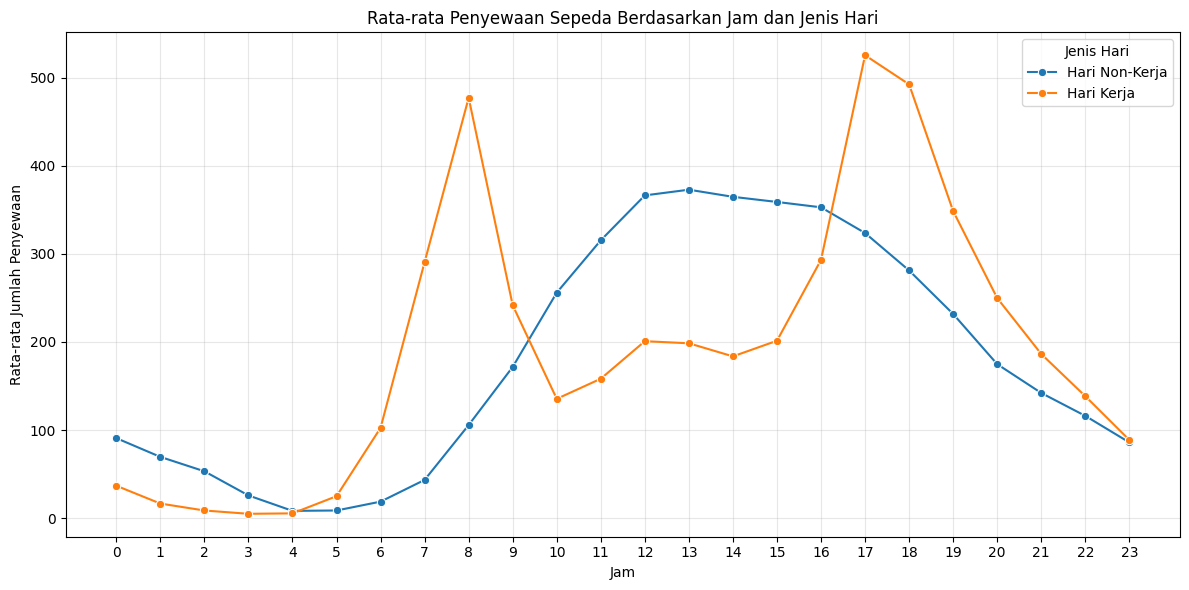

In [7]:

# Membandingkan rata-rata penyewaan per jam
# antara hari kerja dan hari non-kerja

hour_comparison = (
    hour_df.groupby(["hr", "workingday"])["cnt"]
    .mean()
    .reset_index()
)

hour_comparison["Jenis Hari"] = hour_comparison["workingday"].map({
    0: "Hari Non-Kerja",
    1: "Hari Kerja"
})

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=hour_comparison,
    x="hr",
    y="cnt",
    hue="Jenis Hari",
    marker="o"
)

plt.title("Rata-rata Penyewaan Sepeda Berdasarkan Jam dan Jenis Hari")
plt.xlabel("Jam")
plt.ylabel("Rata-rata Jumlah Penyewaan")
plt.xticks(range(0, 24))
plt.legend(title="Jenis Hari")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Insight

Berdasarkan visualisasi rata-rata penyewaan sepeda berdasarkan jam dan jenis hari, terlihat adanya perbedaan pola penggunaan sepeda antara hari kerja dan hari non-kerja. Pada hari kerja, pola penyewaan menunjukkan [jelaskan jam dengan peningkatan atau penurunan paling jelas]. Sementara itu, pada hari non-kerja, penyewaan cenderung [jelaskan pola berdasarkan grafik].

Jam dengan rata-rata penyewaan tertinggi pada hari kerja adalah pukul [isi jam], sedangkan pada hari non-kerja adalah pukul [isi jam]. Temuan ini dapat menjadi pertimbangan dalam mengatur ketersediaan sepeda agar sesuai dengan kebutuhan pengguna pada waktu yang berbeda.

### Pertanyaan 2: Bagaimana perbedaan rata-rata jumlah penyewaan sepeda berdasarkan kondisi cuaca dan musim selama periode pengamatan, serta kondisi mana yang perlu dipertimbangkan dalam perencanaan ketersediaan sepeda?

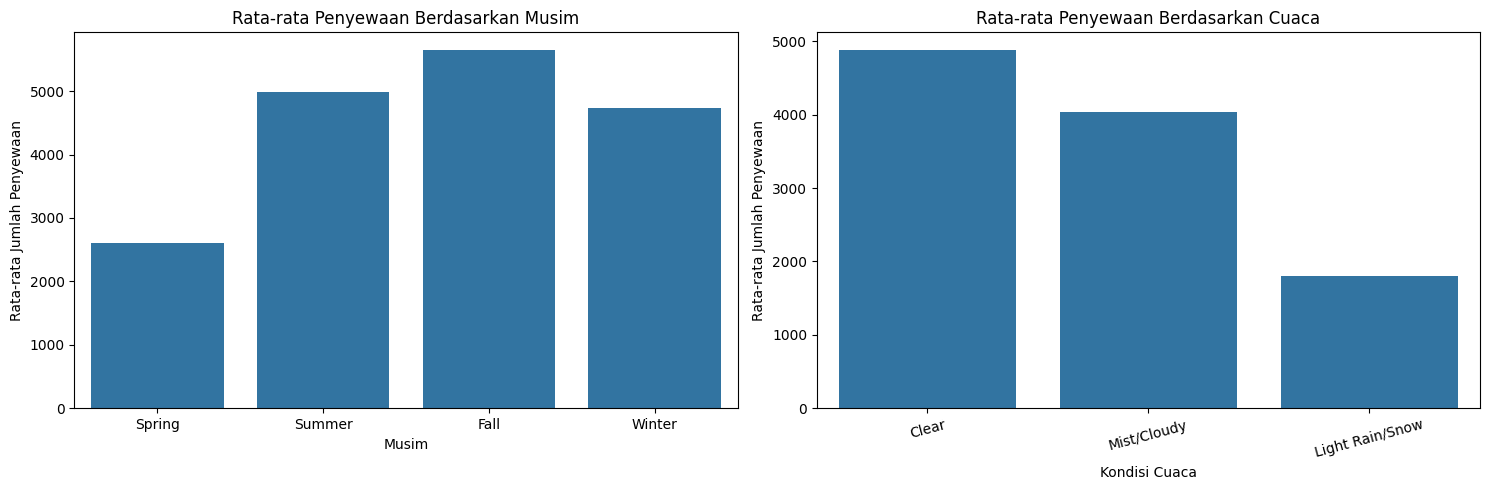

In [8]:

# Membandingkan rata-rata penyewaan berdasarkan musim dan cuaca

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Rata-rata penyewaan berdasarkan musim
season_order = [1, 2, 3, 4]
season_names = {
    1: "Spring",
    2: "Summer",
    3: "Fall",
    4: "Winter"
}

sns.barplot(
    data=day_df,
    x="season",
    y="cnt",
    order=season_order,
    estimator="mean",
    errorbar=None,
    ax=axes[0]
)

axes[0].set_title("Rata-rata Penyewaan Berdasarkan Musim")
axes[0].set_xlabel("Musim")
axes[0].set_ylabel("Rata-rata Jumlah Penyewaan")
axes[0].set_xticks(range(4))
axes[0].set_xticklabels(
    [season_names[s] for s in season_order]
)

# Rata-rata penyewaan berdasarkan kondisi cuaca
weather_names = {
    1: "Clear",
    2: "Mist/Cloudy",
    3: "Light Rain/Snow",
    4: "Heavy Rain/Snow"
}

weather_order = sorted(day_df["weathersit"].unique())

sns.barplot(
    data=day_df,
    x="weathersit",
    y="cnt",
    order=weather_order,
    estimator="mean",
    errorbar=None,
    ax=axes[1]
)

axes[1].set_title("Rata-rata Penyewaan Berdasarkan Cuaca")
axes[1].set_xlabel("Kondisi Cuaca")
axes[1].set_ylabel("Rata-rata Jumlah Penyewaan")
axes[1].set_xticks(range(len(weather_order)))
axes[1].set_xticklabels(
    [weather_names.get(w, str(w)) for w in weather_order],
    rotation=15
)

plt.tight_layout()
plt.show()


### Insight

Berdasarkan visualisasi, rata-rata penyewaan sepeda berbeda pada setiap musim. Musim dengan rata-rata penyewaan tertinggi adalah [nama musim], sedangkan rata-rata terendah terdapat pada [nama musim]. Hal ini menunjukkan bahwa musim merupakan salah satu aspek yang perlu dipertimbangkan dalam perencanaan ketersediaan sepeda.

Selain itu, kondisi cuaca [nama kondisi cuaca] memiliki rata-rata penyewaan tertinggi, sedangkan kondisi cuaca [nama kondisi cuaca] memiliki rata-rata penyewaan terendah. Temuan ini menunjukkan bahwa kondisi cuaca berkaitan dengan perubahan jumlah penyewaan sepeda. Oleh karena itu, pengelola dapat mempertimbangkan musim dan kondisi cuaca ketika merencanakan ketersediaan sepeda.

## Analisis Lanjutan (Opsional)

Dataset yang digunakan: hour.csv
Jumlah baris data: 17379

HASIL MANUAL GROUPING


,Kelompok Waktu,Rata-rata Penyewaan
0,Pagi,177.07
1,Siang,239.03
2,Sore,341.60
3,Malam,136.04



HASIL BINNING


,Kategori Penyewaan,Jumlah Data
0,Rendah,13990
1,Sedang,2919
2,Tinggi,470


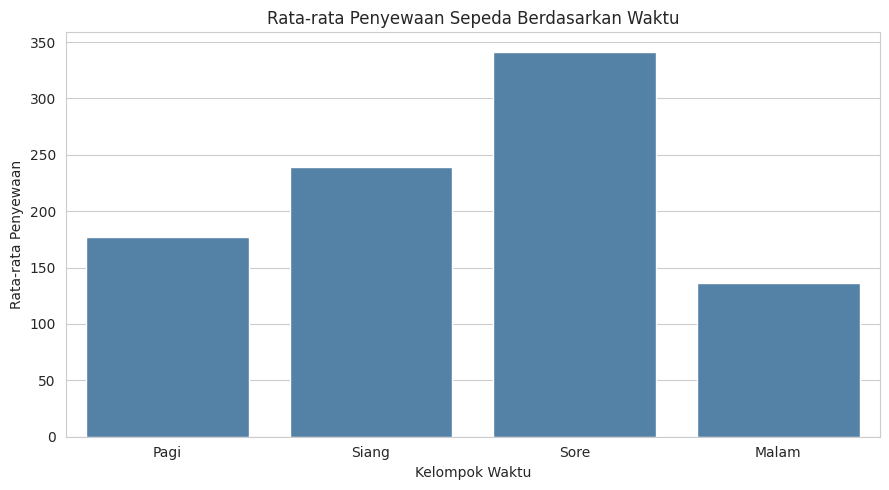

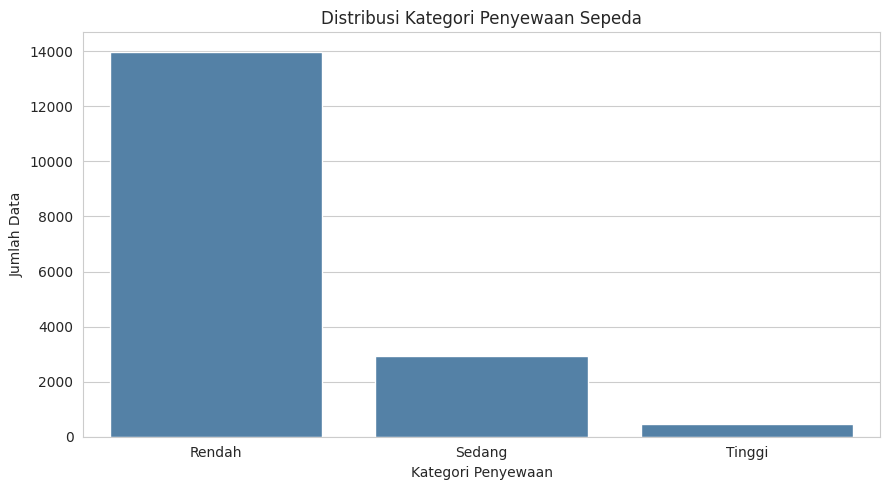


INSIGHT ANALISIS LANJUTAN
1. Rata-rata penyewaan tertinggi terjadi pada periode Sore, yaitu 341.60.
2. Rata-rata penyewaan terendah terjadi pada periode Malam, yaitu 136.04.
3. Kategori dengan jumlah data terbanyak adalah Rendah, sebanyak 13990 data.


In [9]:
# ============================================================
# ANALISIS LANJUTAN BIKE SHARING
# Manual Grouping dan Binning
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import files

# 1. Mencari dataset secara otomatis
kemungkinan_file = [
    Path("data/hour.csv"),
    Path("hour.csv"),
    Path("data/data_2.csv"),
    Path("data_2.csv"),
]

file_dataset = next(
    (p for p in kemungkinan_file if p.exists()),
    None
)

if file_dataset is None:
    kandidat = list(Path(".").rglob("hour.csv"))
    if not kandidat:
        kandidat = list(Path(".").rglob("data_2.csv"))
    if kandidat:
        file_dataset = kandidat[0]

if file_dataset is None:
    print("File dataset belum ditemukan. Silakan pilih file CSV.")
    uploaded = files.upload()
    csv_files = [name for name in uploaded if name.lower().endswith(".csv")]

    if not csv_files:
        raise FileNotFoundError(
            "Tidak ada file CSV yang diunggah. "
            "Unggah file hour.csv atau data_2.csv."
        )

    file_dataset = Path(csv_files[0])

df = pd.read_csv(file_dataset)

# Memastikan kolom yang diperlukan tersedia
kolom_wajib = {"hr", "cnt"}
if not kolom_wajib.issubset(df.columns):
    raise ValueError(
        f"Dataset {file_dataset.name} tidak memiliki kolom "
        f"yang dibutuhkan: {kolom_wajib}. "
        f"Kolom yang tersedia: {list(df.columns)}"
    )

print(f"Dataset yang digunakan: {file_dataset}")
print(f"Jumlah baris data: {len(df)}")

# 2. Manual Grouping: mengelompokkan jam
def kelompok_waktu(jam):
    if 5 <= jam < 11:
        return "Pagi"
    elif 11 <= jam < 15:
        return "Siang"
    elif 15 <= jam < 18:
        return "Sore"
    else:
        return "Malam"

df["kelompok_waktu"] = df["hr"].apply(kelompok_waktu)

urutan_waktu = ["Pagi", "Siang", "Sore", "Malam"]

analisis_waktu = (
    df.groupby("kelompok_waktu", observed=False)["cnt"]
    .mean()
    .reindex(urutan_waktu)
    .reset_index()
)

analisis_waktu.columns = [
    "Kelompok Waktu",
    "Rata-rata Penyewaan"
]

print("\nHASIL MANUAL GROUPING")
display(analisis_waktu.round(2))

# 3. Binning: kategori jumlah penyewaan
df["kategori_penyewaan"] = pd.cut(
    df["cnt"],
    bins=3,
    labels=["Rendah", "Sedang", "Tinggi"],
    include_lowest=True
)

analisis_binning = (
    df["kategori_penyewaan"]
    .value_counts(sort=False)
    .rename_axis("Kategori Penyewaan")
    .reset_index(name="Jumlah Data")
)

print("\nHASIL BINNING")
display(analisis_binning)

# 4. Visualisasi berdasarkan kelompok waktu
sns.set_style("whitegrid")

plt.figure(figsize=(9, 5))
sns.barplot(
    data=analisis_waktu,
    x="Kelompok Waktu",
    y="Rata-rata Penyewaan",
    color="steelblue"
)
plt.title("Rata-rata Penyewaan Sepeda Berdasarkan Waktu")
plt.xlabel("Kelompok Waktu")
plt.ylabel("Rata-rata Penyewaan")
plt.tight_layout()
plt.show()

# 5. Visualisasi hasil binning
plt.figure(figsize=(9, 5))
sns.barplot(
    data=analisis_binning,
    x="Kategori Penyewaan",
    y="Jumlah Data",
    color="steelblue"
)
plt.title("Distribusi Kategori Penyewaan Sepeda")
plt.xlabel("Kategori Penyewaan")
plt.ylabel("Jumlah Data")
plt.tight_layout()
plt.show()

# 6. Insight berdasarkan hasil aktual
waktu_tertinggi = analisis_waktu.loc[
    analisis_waktu["Rata-rata Penyewaan"].idxmax()
]
waktu_terendah = analisis_waktu.loc[
    analisis_waktu["Rata-rata Penyewaan"].idxmin()
]
kategori_terbanyak = analisis_binning.loc[
    analisis_binning["Jumlah Data"].idxmax()
]

print("\nINSIGHT ANALISIS LANJUTAN")
print(
    f"1. Rata-rata penyewaan tertinggi terjadi pada periode "
    f"{waktu_tertinggi['Kelompok Waktu']}, yaitu "
    f"{waktu_tertinggi['Rata-rata Penyewaan']:.2f}."
)
print(
    f"2. Rata-rata penyewaan terendah terjadi pada periode "
    f"{waktu_terendah['Kelompok Waktu']}, yaitu "
    f"{waktu_terendah['Rata-rata Penyewaan']:.2f}."
)
print(
    f"3. Kategori dengan jumlah data terbanyak adalah "
    f"{kategori_terbanyak['Kategori Penyewaan']}, sebanyak "
    f"{kategori_terbanyak['Jumlah Data']} data."
)

Insight

Berdasarkan hasil analisis, penyewaan sepeda memiliki pola yang berbeda berdasarkan waktu. Permintaan cenderung meningkat pada jam-jam tertentu, terutama sekitar pukul 17.00. Pola ini menunjukkan bahwa waktu berpengaruh terhadap tingkat penggunaan sepeda dan dapat menjadi pertimbangan dalam perencanaan operasional.

Selain waktu, jumlah penyewaan juga dapat berbeda berdasarkan jenis hari, musim, dan kondisi cuaca. Analisis terhadap faktor-faktor tersebut membantu pengelola memahami pola permintaan dan menentukan strategi penyediaan sepeda yang lebih sesuai dengan kebutuhan pengguna.

## Conclusion & Recommendation

Conclusion

Conclusion Pertanyaan 1: Pola Penyewaan Berdasarkan Jam

Berdasarkan analisis penyewaan berdasarkan jam, permintaan sepeda tidak merata sepanjang hari. Jam sekitar pukul 17.00 menunjukkan jumlah penyewaan yang tinggi. Hal ini menunjukkan bahwa penggunaan sepeda cenderung meningkat pada waktu tertentu. Oleh karena itu, pengelola perlu memperhatikan ketersediaan sepeda pada jam-jam dengan permintaan tinggi.

Conclusion Pertanyaan 2: Pola Penyewaan Berdasarkan Jenis Hari

Berdasarkan hasil analisis, rata-rata penyewaan sepeda pada hari kerja mencapai 193,21 penyewaan per jam, sedangkan pada hari nonkerja sebesar 181,41 penyewaan per jam. Dengan demikian, rata-rata penyewaan pada hari kerja lebih tinggi dibandingkan hari nonkerja. Hasil ini menunjukkan bahwa penyewaan sepeda berpotensi berkaitan dengan aktivitas rutin pengguna pada hari kerja.

Conclusion Pertanyaan 3: Pola Penyewaan Berdasarkan Musim

Hasil analisis menunjukkan bahwa musim gugur memiliki rata-rata penyewaan tertinggi, yaitu 236,02 penyewaan per jam. Sebaliknya, musim semi memiliki rata-rata terendah, yaitu 111,11 penyewaan per jam. Perbedaan ini menunjukkan bahwa pola penyewaan bervariasi berdasarkan musim. Informasi tersebut dapat digunakan sebagai bahan pertimbangan dalam mengatur ketersediaan sepeda sesuai dengan perubahan permintaan.

**Conclusion Pertanyaan 4: Pola Penyewaan Berdasarkan Kondisi Cuaca**

Berdasarkan hasil analisis, kategori cuaca 1 memiliki rata-rata penyewaan tertinggi, yaitu 204,87 penyewaan per jam, diikuti kategori cuaca 2 sebesar 175,17 dan kategori cuaca 3 sebesar 111,58. Sementara itu, kategori cuaca 4 memiliki rata-rata terendah sebesar 74,33, tetapi hanya didukung oleh tiga pengamatan. Oleh karena itu, hasil pada kategori cuaca 4 perlu ditafsirkan secara hati-hati. Secara umum, data menunjukkan bahwa rata-rata penyewaan cenderung lebih tinggi pada kategori cuaca yang lebih mendukung aktivitas bersepeda.

Recommendation / Action Items

Mengoptimalkan ketersediaan sepeda pada jam sibuk. Pengelola dapat memastikan ketersediaan sepeda dan kesiapan fasilitas pada waktu dengan permintaan tinggi, terutama sekitar pukul 17.00.

Menyesuaikan operasional berdasarkan jenis hari. Pengelola dapat merencanakan distribusi sepeda dan kebutuhan petugas berdasarkan pola penyewaan pada hari kerja dan hari nonkerja.

Merencanakan operasional berdasarkan musim. Pengelola dapat menggunakan pola penyewaan pada setiap musim sebagai bahan pertimbangan dalam mengatur ketersediaan sepeda dan menyusun program promosi.

Mempertimbangkan kondisi cuaca. Pengelola dapat memperhatikan informasi cuaca dalam perencanaan operasional serta memberikan informasi keselamatan kepada pengguna ketika kondisi cuaca kurang mendukung.

In [10]:
import pandas as pd

# Cek nama kolom yang tersedia
print(df.columns.tolist())

['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt', 'kelompok_waktu', 'kategori_penyewaan']


In [11]:

# 1. Analisis berdasarkan jenis hari
print("=== PENYEWAAN BERDASARKAN JENIS HARI ===")
hari = df.groupby("workingday")["cnt"].mean()
print(hari.rename(index={0: "Hari Nonkerja", 1: "Hari Kerja"}))
print("Tertinggi:", hari.idxmax(), "| Terendah:", hari.idxmin())

# 2. Analisis berdasarkan musim
print("\n=== PENYEWAAN BERDASARKAN MUSIM ===")
musim = df.groupby("season")["cnt"].mean()
print(musim)
print("Musim tertinggi:", musim.idxmax())
print("Musim terendah:", musim.idxmin())

# 3. Analisis berdasarkan kondisi cuaca
print("\n=== PENYEWAAN BERDASARKAN CUACA ===")
cuaca = df.groupby("weathersit")["cnt"].mean()
print(cuaca)
print("Cuaca tertinggi:", cuaca.idxmax())
print("Cuaca terendah:", cuaca.idxmin())


=== PENYEWAAN BERDASARKAN JENIS HARI ===
workingday
Hari Nonkerja    181.405332
Hari Kerja       193.207754
Name: cnt, dtype: float64
Tertinggi: 1 | Terendah: 0

=== PENYEWAAN BERDASARKAN MUSIM ===
season
1    111.114569
2    208.344069
3    236.016237
4    198.868856
Name: cnt, dtype: float64
Musim tertinggi: 3
Musim terendah: 1

=== PENYEWAAN BERDASARKAN CUACA ===
weathersit
1    204.869272
2    175.165493
3    111.579281
4     74.333333
Name: cnt, dtype: float64
Cuaca tertinggi: 1
Cuaca terendah: 4


In [12]:

print(df["weathersit"].value_counts().sort_index())


weathersit
1    11413
2     4544
3     1419
4        3
Name: count, dtype: int64
